In [ ]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    if root.count("/") >= 4:
        break

In [ ]:
import os
base = "/kaggle/input/datasets/nirmalsankalana"
for name in os.listdir(base):
    p = os.path.join(base, name)
    print(p)
    for sub in os.listdir(p):
        print("   ", sub)

In [ ]:
import os
base = "/kaggle/input/datasets/nirmalsankalana/plantdoc-dataset"
for split in ["train", "test"]:
    print("==", split)
    for cls in sorted(os.listdir(f"{base}/{split}")):
        n = len(os.listdir(f"{base}/{split}/{cls}"))
        print(f"{cls}: {n}")

In [ ]:
import os, shutil
base = "/kaggle/input/datasets/nirmalsankalana/plantdoc-dataset"
out = "/kaggle/working/data/real_test"

mapping = {
    "Potato_leaf_early_blight": "Potato___Early_blight",
    "Potato_leaf_late_blight": "Potato___Late_blight",
    "Tomato_leaf_bacterial_spot": "Tomato___Bacterial_spot",
    "Tomato_Early_blight_leaf": "Tomato___Early_blight",
    "Tomato_leaf_late_blight": "Tomato___Late_blight",
    "Tomato_mold_leaf": "Tomato___Leaf_Mold",
    "Tomato_leaf_mosaic_virus": "Tomato___Mosaic_virus",
    "Tomato_Septoria_leaf_spot": "Tomato___Septoria_leaf_spot",
    "Tomato_two_spotted_spider_mites_leaf": "Tomato___Spider_mites",
    "Tomato_leaf_yellow_virus": "Tomato___Yellow_Leaf_Curl_Virus",
    "Tomato_leaf": "Tomato___healthy",
}

for src, dst in mapping.items():
    os.makedirs(f"{out}/{dst}", exist_ok=True)
    for split in ["train", "test"]:
        p = f"{base}/{split}/{src}"
        if not os.path.isdir(p):
            continue
        for f in os.listdir(p):
            shutil.copy(f"{p}/{f}", f"{out}/{dst}/{split}_{f}")

for c in sorted(os.listdir(out)):
    print(c, len(os.listdir(f"{out}/{c}")))

In [ ]:
import os
base = "/kaggle/input/datasets"
for owner in os.listdir(base):
    for ds in os.listdir(f"{base}/{owner}"):
        print(f"{base}/{owner}/{ds}", os.listdir(f"{base}/{owner}/{ds}"))

In [ ]:
import os
base = "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"
for c in sorted(os.listdir(base)):
    print(c, len(os.listdir(f"{base}/{c}")))

In [4]:
import os, time, numpy as np
from PIL import Image

base = "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"
folders = [c for c in sorted(os.listdir(base)) if not c.startswith("Pepper")]

def hashes8(path):
    im = Image.open(path); im.draft("L", (64, 64))
    a = np.asarray(im.convert("L").resize((16, 16)), dtype=np.float32)
    out = []
    for flip in (False, True):
        b = np.fliplr(a) if flip else a
        for k in range(4):
            r = np.rot90(b, k)
            out.append(np.packbits((r > r.mean()).flatten()))
    return np.stack(out)

t = time.time()
paths, labels, H, bad = [], [], [], []
for c in folders:
    for f in sorted(os.listdir(f"{base}/{c}")):
        p = f"{base}/{c}/{f}"
        try:
            h = hashes8(p)
        except Exception:
            bad.append(p)
            continue
        paths.append(p); labels.append(c); H.append(h)
    print(c, "done |", len(paths), "images |", round(time.time() - t), "sec", flush=True)
H = np.stack(H)
np.savez("/kaggle/working/hashes.npz", paths=paths, labels=labels, H=H)
print(len(paths), H.shape, "skipped:", len(bad))

Potato___Early_blight done | 1000 images | 2 sec
Potato___Late_blight done | 2000 images | 3 sec
Potato___healthy done | 2152 images | 3 sec
Tomato_Bacterial_spot done | 4279 images | 7 sec
Tomato_Early_blight done | 5279 images | 8 sec
Tomato_Late_blight done | 7188 images | 11 sec
Tomato_Leaf_Mold done | 8140 images | 12 sec
Tomato_Septoria_leaf_spot done | 9911 images | 15 sec
Tomato_Spider_mites_Two_spotted_spider_mite done | 11587 images | 18 sec
Tomato__Target_Spot done | 12991 images | 20 sec
Tomato__Tomato_YellowLeaf__Curl_Virus done | 16199 images | 168 sec
Tomato__Tomato_mosaic_virus done | 16572 images | 181 sec
Tomato_healthy done | 18163 images | 257 sec
18163 (18163, 8, 32) skipped: 1


In [5]:
import numpy as np, torch
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

d = np.load("/kaggle/working/hashes.npz")
paths, labels, H = d["paths"], d["labels"], d["H"]
N = len(paths)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, flush=True)
T = 6   # max different bits (out of 256) to call two images near-copies

bits = torch.tensor(np.unpackbits(H, axis=2).astype(np.float32) * 2 - 1, device=dev)
A = bits[:, 0, :]

rows, cols, total = [], [], 0
for s in range(0, N, 2000):
    a = A[s:s + 2000]
    for v in range(8):
        ham = (256 - a @ bits[:, v, :].T) / 2
        i, j = torch.nonzero(ham <= T, as_tuple=True)
        i = i + s
        keep = i != j
        rows.append(i[keep].cpu().numpy()); cols.append(j[keep].cpu().numpy())
        total += int(keep.sum())
    print("done", min(s + 2000, N), "of", N, "| pairs so far:", total, flush=True)
    if total > 5_000_000:
        print("Too many pairs, stopping. Tell Claude."); break

rows = np.concatenate(rows); cols = np.concatenate(cols)
g = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(N, N))
n_groups, group = connected_components(g, directed=False)
np.save("/kaggle/working/groups.npy", group)

sizes = np.bincount(group)
print("images:", N, "| groups:", n_groups)
print("groups with more than 1 image:", int((sizes > 1).sum()))
print("images inside such groups:", int(sizes[sizes > 1].sum()))
print("largest group:", sizes.max())
mixed = sum(len(set(labels[group == k])) > 1 for k in np.where(sizes > 1)[0])
print("groups mixing different classes:", mixed)

device: cuda
done 2000 of 18163 | pairs so far: 0
done 4000 of 18163 | pairs so far: 2
done 6000 of 18163 | pairs so far: 10
done 8000 of 18163 | pairs so far: 21
done 10000 of 18163 | pairs so far: 21
done 12000 of 18163 | pairs so far: 22
done 14000 of 18163 | pairs so far: 23
done 16000 of 18163 | pairs so far: 23
done 18000 of 18163 | pairs so far: 38
done 18163 of 18163 | pairs so far: 40
images: 18163 | groups: 18143
groups with more than 1 image: 20
images inside such groups: 40
largest group: 2
groups mixing different classes: 2


In [6]:
import numpy as np, torch, torchvision, time
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

d = np.load("/kaggle/working/hashes.npz")
paths, labels = d["paths"], d["labels"]
dev = "cuda"
tf = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

class DS(Dataset):
    def __len__(self): return len(paths)
    def __getitem__(self, i): return tf(Image.open(paths[i]).convert("RGB"))

m = torchvision.models.mobilenet_v3_small(weights="IMAGENET1K_V1")
m.classifier = torch.nn.Identity()
m = m.to(dev).eval()

t = time.time(); feats = []
with torch.no_grad():
    for k, x in enumerate(DataLoader(DS(), batch_size=128, num_workers=2)):
        f = m(x.to(dev))
        feats.append(torch.nn.functional.normalize(f, dim=1).cpu())
        if k % 20 == 0: print(k * 128, "images |", round(time.time() - t), "sec", flush=True)
F = torch.cat(feats).numpy()
np.save("/kaggle/working/feats.npy", F)

Ft = torch.tensor(F, device=dev)
nn_sim = np.zeros(len(paths), dtype=np.float32)
for c in np.unique(labels):
    idx = np.where(labels == c)[0]
    S = Ft[idx] @ Ft[idx].T
    S.fill_diagonal_(-1)
    nn_sim[idx] = S.max(1).values.cpu().numpy()
print("images whose closest same-class image has similarity above:")
for th in (0.99, 0.97, 0.95, 0.90):
    print(th, int((nn_sim > th).sum()))

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 87.2MB/s]


0 images | 6 sec
2560 images | 11 sec
5120 images | 16 sec
7680 images | 22 sec
10240 images | 28 sec
12800 images | 34 sec
15360 images | 40 sec
17920 images | 46 sec
images whose closest same-class image has similarity above:
0.99 30
0.97 1171
0.95 5945
0.9 17373


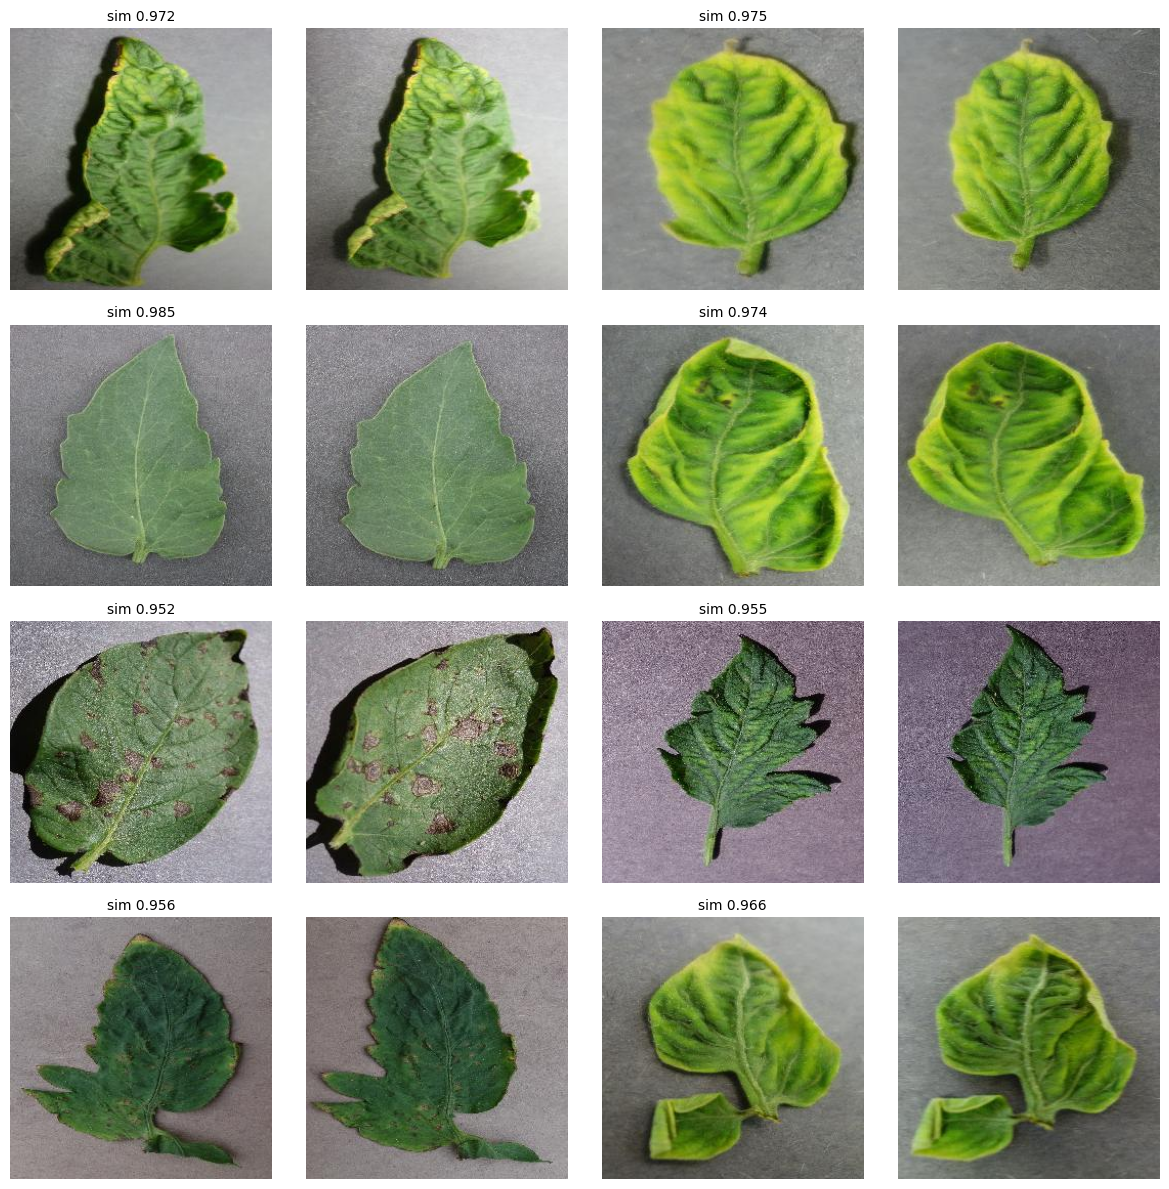

In [7]:
import numpy as np, torch, matplotlib.pyplot as plt
from PIL import Image

d = np.load("/kaggle/working/hashes.npz")
paths, labels = d["paths"], d["labels"]
F = np.load("/kaggle/working/feats.npy")
Ft = torch.tensor(F, device="cuda")

nn_sim = np.zeros(len(paths), dtype=np.float32)
nn_idx = np.zeros(len(paths), dtype=np.int64)
for c in np.unique(labels):
    idx = np.where(labels == c)[0]
    S = Ft[idx] @ Ft[idx].T
    S.fill_diagonal_(-1)
    v, j = S.max(1)
    nn_sim[idx] = v.cpu().numpy()
    nn_idx[idx] = idx[j.cpu().numpy()]

rng = np.random.default_rng(0)
bandA = np.where((nn_sim > 0.97) & (nn_sim <= 0.99))[0]
bandB = np.where((nn_sim > 0.95) & (nn_sim <= 0.97))[0]
pairs = list(rng.choice(bandA, 4, replace=False)) + list(rng.choice(bandB, 4, replace=False))

fig, ax = plt.subplots(4, 4, figsize=(12, 12))
for n, i in enumerate(pairs):
    r, c = divmod(n, 2)
    for k, p in enumerate((paths[i], paths[nn_idx[i]])):
        a = ax[r][c * 2 + k]
        a.imshow(Image.open(p).convert("RGB")); a.axis("off")
        if k == 0: a.set_title(f"sim {nn_sim[i]:.3f}", fontsize=10)
plt.tight_layout(); plt.show()

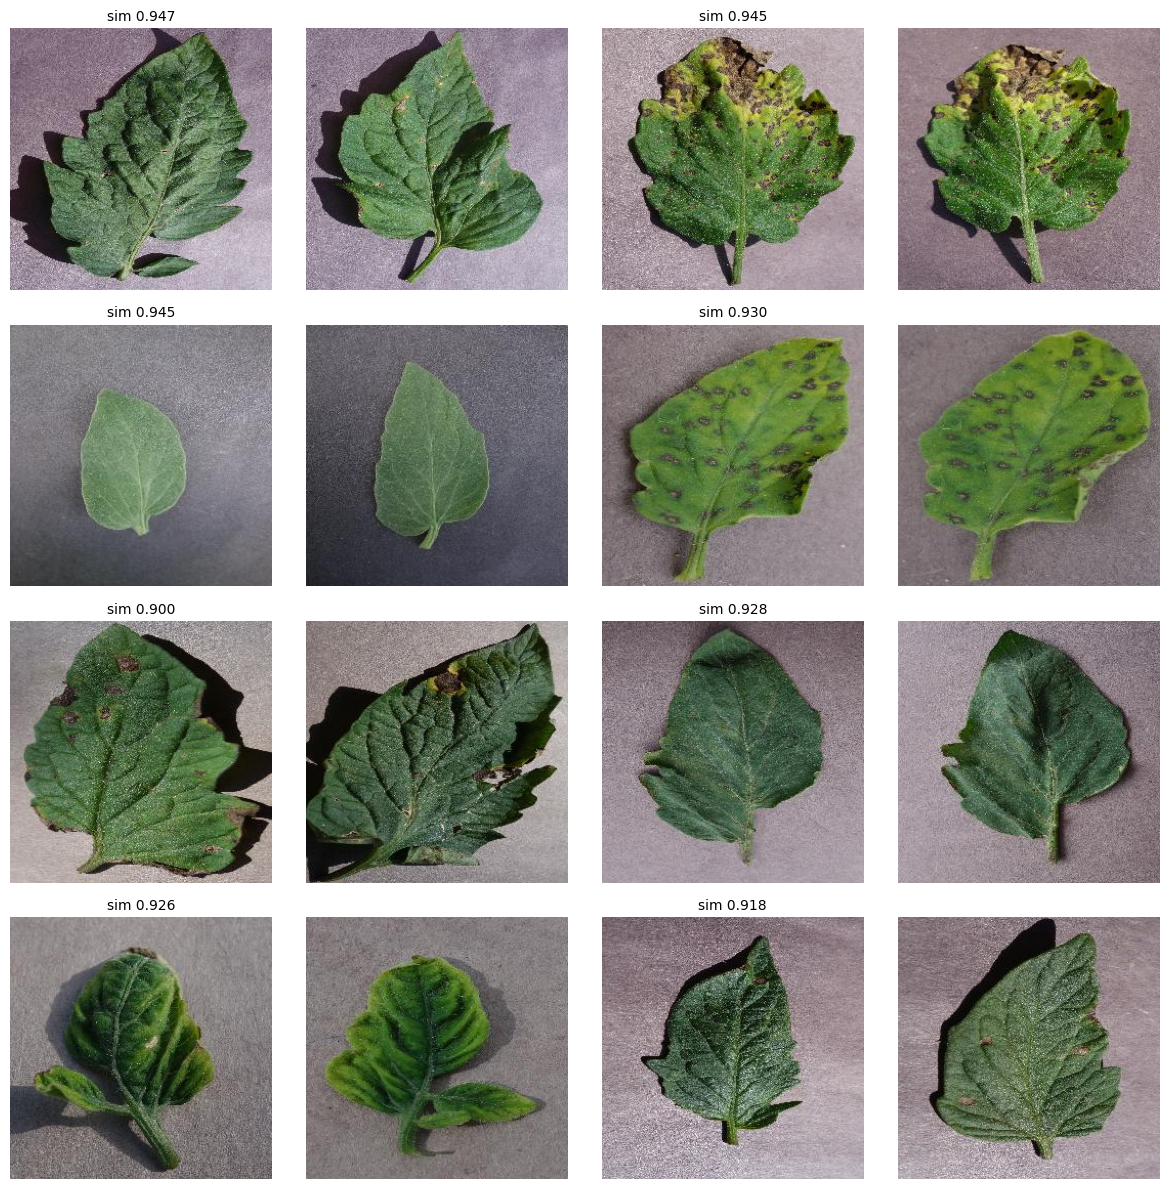

In [8]:
import numpy as np, torch, matplotlib.pyplot as plt
from PIL import Image

d = np.load("/kaggle/working/hashes.npz")
paths, labels = d["paths"], d["labels"]
F = np.load("/kaggle/working/feats.npy")
Ft = torch.tensor(F, device="cuda")

nn_sim = np.zeros(len(paths), dtype=np.float32)
nn_idx = np.zeros(len(paths), dtype=np.int64)
for c in np.unique(labels):
    idx = np.where(labels == c)[0]
    S = Ft[idx] @ Ft[idx].T
    S.fill_diagonal_(-1)
    v, j = S.max(1)
    nn_sim[idx] = v.cpu().numpy()
    nn_idx[idx] = idx[j.cpu().numpy()]
np.save("/kaggle/working/nn_sim.npy", nn_sim)

rng = np.random.default_rng(1)
bandA = np.where((nn_sim > 0.93) & (nn_sim <= 0.95))[0]
bandB = np.where((nn_sim > 0.88) & (nn_sim <= 0.93))[0]
pairs = list(rng.choice(bandA, 4, replace=False)) + list(rng.choice(bandB, 4, replace=False))

fig, ax = plt.subplots(4, 4, figsize=(12, 12))
for n, i in enumerate(pairs):
    r, c = divmod(n, 2)
    for k, p in enumerate((paths[i], paths[nn_idx[i]])):
        a = ax[r][c * 2 + k]
        a.imshow(Image.open(p).convert("RGB")); a.axis("off")
        if k == 0: a.set_title(f"sim {nn_sim[i]:.3f}", fontsize=10)
plt.tight_layout(); plt.show()

In [9]:
import numpy as np, torch
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

d = np.load("/kaggle/working/hashes.npz")
paths, labels = d["paths"], d["labels"]
F = np.load("/kaggle/working/feats.npy")
Ft = torch.tensor(F, device="cuda")
N = len(paths)

def make_groups(th):
    group = np.zeros(N, dtype=np.int64); offset = 0
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        S = Ft[idx] @ Ft[idx].T
        i, j = torch.nonzero(S > th, as_tuple=True)
        i, j = i.cpu().numpy(), j.cpu().numpy()
        g = coo_matrix((np.ones(len(i)), (i, j)), shape=(len(idx), len(idx)))
        n, comp = connected_components(g, directed=False)
        group[idx] = comp + offset; offset += n
    return group

for th in (0.95, 0.93):
    group = make_groups(th)
    np.save(f"/kaggle/working/groups_{int(th*100)}.npy", group)
    sizes = np.bincount(group)
    print(f"--- threshold {th}: groups {len(sizes)} | largest group {sizes.max()}")
    for c in np.unique(labels):
        s = np.bincount(group[labels == c])
        s = s[s > 0]
        print(f"  {c}: {int((labels == c).sum())} images -> {len(s)} groups, largest {s.max()}")

--- threshold 0.95: groups 13471 | largest group 518
  Potato___Early_blight: 1000 images -> 856 groups, largest 23
  Potato___Late_blight: 1000 images -> 976 groups, largest 3
  Potato___healthy: 152 images -> 66 groups, largest 84
  Tomato_Bacterial_spot: 2127 images -> 1519 groups, largest 166
  Tomato_Early_blight: 1000 images -> 987 groups, largest 3
  Tomato_Late_blight: 1909 images -> 1659 groups, largest 7
  Tomato_Leaf_Mold: 952 images -> 924 groups, largest 5
  Tomato_Septoria_leaf_spot: 1771 images -> 1474 groups, largest 8
  Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images -> 1199 groups, largest 306
  Tomato__Target_Spot: 1404 images -> 1187 groups, largest 49
  Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images -> 1726 groups, largest 518
  Tomato__Tomato_mosaic_virus: 373 images -> 235 groups, largest 80
  Tomato_healthy: 1591 images -> 663 groups, largest 483
--- threshold 0.93: groups 5550 | largest group 2633
  Potato___Early_blight: 1000 images -> 152 groups,

In [10]:
import numpy as np, os, shutil, json, random
d = np.load("/kaggle/working/hashes.npz")
paths, labels = d["paths"], d["labels"]
group = np.load("/kaggle/working/groups_95.npy")

rename = {
 "Potato___Early_blight":"Potato___Early_blight","Potato___Late_blight":"Potato___Late_blight",
 "Potato___healthy":"Potato___healthy","Tomato_Bacterial_spot":"Tomato___Bacterial_spot",
 "Tomato_Early_blight":"Tomato___Early_blight","Tomato_Late_blight":"Tomato___Late_blight",
 "Tomato_Leaf_Mold":"Tomato___Leaf_Mold","Tomato_Septoria_leaf_spot":"Tomato___Septoria_leaf_spot",
 "Tomato_Spider_mites_Two_spotted_spider_mite":"Tomato___Spider_mites",
 "Tomato__Target_Spot":"Tomato___Target_Spot",
 "Tomato__Tomato_YellowLeaf__Curl_Virus":"Tomato___Yellow_Leaf_Curl_Virus",
 "Tomato__Tomato_mosaic_virus":"Tomato___Mosaic_virus","Tomato_healthy":"Tomato___healthy"}
classes = sorted(rename.values())
expected = ["Potato___Early_blight","Potato___Late_blight","Potato___healthy","Tomato___Bacterial_spot",
 "Tomato___Early_blight","Tomato___Late_blight","Tomato___Leaf_Mold","Tomato___Mosaic_virus",
 "Tomato___Septoria_leaf_spot","Tomato___Spider_mites","Tomato___Target_Spot",
 "Tomato___Yellow_Leaf_Curl_Virus","Tomato___healthy"]
assert classes == expected, "class order changed!"

rng = random.Random(42)
frac = {"train":0.70, "val":0.15, "test":0.15}
cap = {"train":1050, "val":225, "test":225}
out = "/kaggle/working/data_v2"
shutil.rmtree(out, ignore_errors=True)
split_of_group = {}
summary = []

for old, new in rename.items():
    idx = np.where(labels == old)[0]
    gids = list(set(group[idx]))
    sizes = {g: int((group[idx] == g).sum()) for g in gids}
    rng.shuffle(gids)
    gids.sort(key=lambda g: -sizes[g])          # biggest groups first
    n = len(idx); got = {"train":0, "val":0, "test":0}
    for g in gids:
        s = max(frac, key=lambda k: frac[k]*n - got[k])   # split with biggest deficit
        split_of_group[g] = s; got[s] += sizes[g]
    chosen = {"train":[], "val":[], "test":[]}
    for i in idx: chosen[split_of_group[group[i]]].append(i)
    for s in chosen:
        if len(chosen[s]) > cap[s]: chosen[s] = rng.sample(chosen[s], cap[s])
        os.makedirs(f"{out}/{s}/{new}", exist_ok=True)
        for i in chosen[s]: shutil.copy(paths[i], f"{out}/{s}/{new}/{os.path.basename(paths[i])}")
    summary.append((new, len(chosen["train"]), len(chosen["val"]), len(chosen["test"])))

json.dump(classes, open("/kaggle/working/classes.json","w"))
print(f"{'class':36s} train  val  test")
for r in summary: print(f"{r[0]:36s} {r[1]:5d} {r[2]:4d} {r[3]:5d}")

# safety check: no group appears in two splits
chk = {}
for s in ("train","val","test"):
    for c in os.listdir(f"{out}/{s}"):
        for f in os.listdir(f"{out}/{s}/{c}"): chk[(c, f)] = s
bad = 0
for i in range(len(paths)):
    key = (rename[labels[i]], os.path.basename(paths[i]))
    if key in chk and chk[key] != split_of_group[group[i]]: bad += 1
print("images in the wrong split:", bad)

class                                train  val  test
Potato___Early_blight                  700  150   150
Potato___Late_blight                   700  150   150
Potato___healthy                       106   23    23
Tomato___Bacterial_spot               1050  225   225
Tomato___Early_blight                  700  150   150
Tomato___Late_blight                  1050  225   225
Tomato___Leaf_Mold                     666  143   143
Tomato___Septoria_leaf_spot           1050  225   225
Tomato___Spider_mites                 1050  225   225
Tomato___Target_Spot                   983  211   210
Tomato___Yellow_Leaf_Curl_Virus       1050  225   225
Tomato___Mosaic_virus                  261   56    56
Tomato___healthy                      1050  225   225
images in the wrong split: 0


In [11]:
import os, shutil, random, json
rng = random.Random(42)
out = "/kaggle/working/data_v2"
pd = "/kaggle/input/datasets/nirmalsankalana/plantdoc-dataset"
pv = "/kaggle/input/datasets/emmarex/plantdisease/PlantVillage"

skip = ("Tomato", "Potato")          # tomato and potato folders are NOT "other"
other_dirs = [c for c in os.listdir(f"{pd}/train") if not c.startswith(skip)]
print("other crops used:", len(other_dirs), "folders")

for s in ("train", "val", "test"):
    shutil.rmtree(f"{out}/{s}/Other", ignore_errors=True)
    os.makedirs(f"{out}/{s}/Other")

def put(src, s, tag):
    shutil.copy(src, f"{out}/{s}/Other/{tag}_{os.path.basename(src)}")

# PlantDoc train photos: 80% to train, 20% to val
pdtrain = [(c, f) for c in other_dirs for f in os.listdir(f"{pd}/train/{c}")]
rng.shuffle(pdtrain)
cut = int(0.8 * len(pdtrain))
for k, (c, f) in enumerate(pdtrain):
    put(f"{pd}/train/{c}/{f}", "train" if k < cut else "val", "pd_" + c)
# PlantDoc test photos: test
for c in other_dirs:
    for f in os.listdir(f"{pd}/test/{c}"):
        put(f"{pd}/test/{c}/{f}", "test", "pd_" + c)
# Pepper (PlantVillage): 500 images, train only
pep = [(c, f) for c in os.listdir(pv) if c.startswith("Pepper") for f in os.listdir(f"{pv}/{c}")]
for c, f in rng.sample(pep, 500):
    put(f"{pv}/{c}/{f}", "train", "pep_" + c)

classes = json.load(open("/kaggle/working/classes.json"))
if "Other" not in classes: classes.append("Other")
json.dump(classes, open("/kaggle/working/classes.json", "w"))

print(len(classes), "classes, last is:", classes[-1])
for s in ("train", "val", "test"):
    print(s, "Other:", len(os.listdir(f"{out}/{s}/Other")))

other crops used: 17 folders
14 classes, last is: Other
train Other: 1691
val Other: 298
test Other: 151


In [12]:
import os
print(os.path.exists("/kaggle/working/data_v2/train/Other"))
print(os.path.exists("/kaggle/working/classes.json"))

True
True


In [13]:
import torch, torch.nn as nn, torchvision, torchvision.transforms as T, numpy as np, os, time, json
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

root = "/kaggle/working/data_v2"
classes = json.load(open("/kaggle/working/classes.json"))
norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tf_train = T.Compose([T.RandomResizedCrop(224, scale=(0.6, 1.0)), T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(), T.RandomRotation(20), T.ColorJitter(0.3, 0.3, 0.3, 0.05),
    T.ToTensor(), norm])
tf_eval = T.Compose([T.Resize((224, 224)), T.ToTensor(), norm])

class DS(ImageFolder):
    def find_classes(self, d): return classes, {c: i for i, c in enumerate(classes)}
tr = DS(f"{root}/train", tf_train); va = DS(f"{root}/val", tf_eval)
assert tr.classes == classes
tl = DataLoader(tr, batch_size=64, shuffle=True, num_workers=4)
vl = DataLoader(va, batch_size=64, num_workers=4)

counts = np.bincount([y for _, y in tr.samples], minlength=len(classes))
w = (1.0 / counts) ** 0.5; w = w / w.mean()
dev = "cuda"
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=dev))

m = torchvision.models.mobilenet_v3_small(weights="IMAGENET1K_V1")
m.classifier[3] = nn.Linear(m.classifier[3].in_features, len(classes))
m = m.to(dev)

def run_epoch(opt=None):
    m.train(opt is not None); loader = tl if opt else vl
    tot = ok = 0; ls = 0.0
    with torch.set_grad_enabled(opt is not None):
        for x, y in loader:
            x, y = x.to(dev), y.to(dev)
            o = m(x); l = loss_fn(o, y)
            if opt: opt.zero_grad(); l.backward(); opt.step()
            ls += l.item() * len(y); tot += len(y); ok += (o.argmax(1) == y).sum().item()
    return ls / tot, ok / tot

best = 0; t0 = time.time()
def stage(name, epochs, lr, params):
    global best
    opt = torch.optim.Adam(params, lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    for e in range(epochs):
        _, tra = run_epoch(opt); sch.step()
        vls, vaa = run_epoch()
        if vaa > best:
            best = vaa; torch.save(m.state_dict(), "/kaggle/working/best_model_v2.pth")
        print(f"{name} {e+1}/{epochs} | train {tra:.4f} | val {vaa:.4f} | best {best:.4f} | {round(time.time()-t0)}s", flush=True)

for p in m.features.parameters(): p.requires_grad = False
stage("head", 4, 1e-3, [p for p in m.parameters() if p.requires_grad])
for p in m.parameters(): p.requires_grad = True
stage("full", 12, 3e-4, m.parameters())
print("done. best val:", best)

head 1/4 | train 0.7355 | val 0.7602 | best 0.7602 | 58s
head 2/4 | train 0.8420 | val 0.8431 | best 0.8431 | 115s
head 3/4 | train 0.8741 | val 0.8692 | best 0.8692 | 171s
head 4/4 | train 0.8880 | val 0.8882 | best 0.8882 | 227s
full 1/12 | train 0.9286 | val 0.8981 | best 0.8981 | 284s
full 2/12 | train 0.9612 | val 0.9475 | best 0.9475 | 341s
full 3/12 | train 0.9732 | val 0.9810 | best 0.9810 | 399s
full 4/12 | train 0.9803 | val 0.9747 | best 0.9810 | 457s
full 5/12 | train 0.9821 | val 0.9818 | best 0.9818 | 516s
full 6/12 | train 0.9858 | val 0.9866 | best 0.9866 | 575s
full 7/12 | train 0.9893 | val 0.9874 | best 0.9874 | 633s
full 8/12 | train 0.9898 | val 0.9881 | best 0.9881 | 691s
full 9/12 | train 0.9936 | val 0.9889 | best 0.9889 | 747s
full 10/12 | train 0.9926 | val 0.9897 | best 0.9897 | 806s
full 11/12 | train 0.9947 | val 0.9913 | best 0.9913 | 864s
full 12/12 | train 0.9948 | val 0.9913 | best 0.9913 | 923s
done. best val: 0.9913077834847887
